# UniAthleteIQ v2: leakage-free injury risk prediction

This notebook replaces the evaluation in `injury_prediction_pipeline.ipynb` (v1) with one that holds up to scrutiny.

| Problem in v1 | Fix in v2 |
|---|---|
| SMOTE and scaling applied **before** the train/test split, so synthetic copies of test rows are in training | Imbalance handled with class weights; SMOTE (when used) runs only inside training folds |
| 33% exact duplicate rows across train and test | Deduplicated in the audit; real models use datasets that have no duplicates |
| Random row split puts the same athlete in train and test | **Athlete-grouped** cross-validation plus a held-out set of athletes the model never sees |
| Accuracy on a 50/50 resampled test set | ROC-AUC and **PR-AUC on the real class balance** (injuries are 1–4% of runner days) |
| Different quantities merged into one column (km → minutes, exertion → fatigue, recovery → risk score) | Each dataset modelled with its own correctly-named features; cross-sport tested explicitly with dataset-normalised features |
| Only 4 numbers per runner-day used | 7-day and 3-week workload features (ACWR, monotony, strain) plus deviation from each athlete's **personal baseline** |
| SHAP mentioned but not done | SHAP explanations for the final model |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

from uniathleteiq import data, evaluation as ev, explain, models, paths, plots

paths.ensure_output_dirs()
plots.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
CH, RES = paths.CHARTS_DIR, paths.RESULTS_DIR

## 1. Audit of the v1 protocol

Same combined dataset and same Random Forest as v1, evaluated three ways:

1. **v1 protocol**: SMOTE on everything, then split.
2. **Correct protocol**: drop duplicates, split first, SMOTE on training rows only, test on the real class balance.
3. **Sport column only**: a model that sees only which sport (that is, which source dataset) the row came from.

In [2]:
v1 = data.load_v1_combined()
V1_FEATURES = ["heart_rate", "fatigue_index", "duration_minutes", "injury_risk_score", "sport_encoded"]
print(f"v1 combined rows: {len(v1):,}   exact duplicates: {v1.duplicated(V1_FEATURES + ['injury_occurred']).sum():,}")
print("Injury rate by 'sport' (= source dataset):")
display(v1.groupby("sport")["injury_occurred"].agg(rows="size", injury_rate="mean"))

audit = ev.leakage_audit(v1, V1_FEATURES)
audit.to_csv(RES / "v1_leakage_audit.csv")
display(audit)

v1 combined rows: 87,865   exact duplicates: 28,991
Injury rate by 'sport' (= source dataset):


,rows,injury_rate
sport,,
Athletics,85564,0.014
Baseball,181,0.646
Basketball,204,0.642
Football,1503,0.939
Soccer,198,0.631
Tennis,215,0.619


,accuracy,f1,precision,recall,roc_auc,pr_auc
protocol,,,,,,
v1: SMOTE before split (leaky),0.963,0.963,0.985,0.941,0.991,0.990
"Correct: dedupe, split, SMOTE on train only",0.962,0.577,0.570,0.585,0.808,0.589
Sport column only (dataset identity),0.975,0.672,0.785,0.587,0.791,0.526


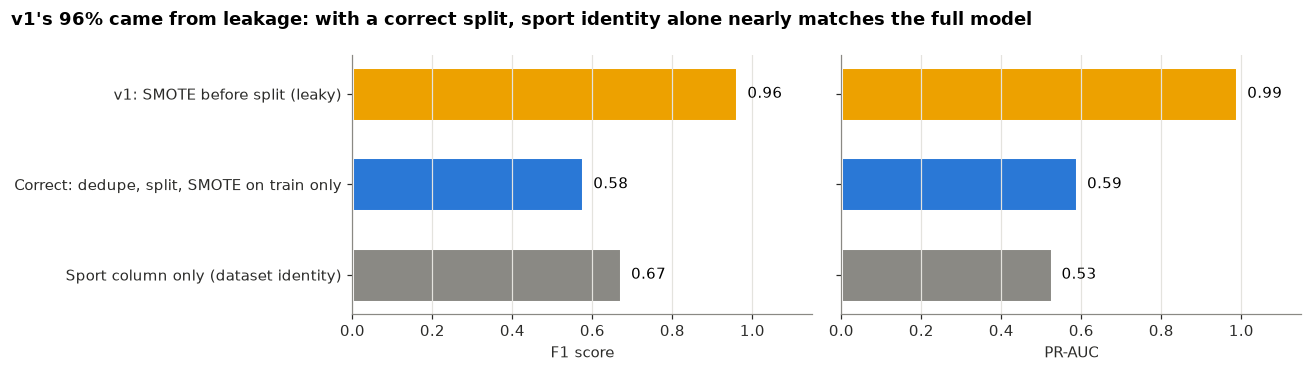

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, metric, label in [(axes[0], "f1", "F1 score"), (axes[1], "pr_auc", "PR-AUC")]:
    vals = audit[metric]
    ax.barh(audit.index, vals, color=[plots.SERIES[3], plots.SERIES[0], plots.MUTED],
            height=0.6, edgecolor="white", linewidth=2)
    for i, v in enumerate(vals):
        ax.text(v, i, f"  {v:.2f}", va="center")
    ax.set(xlim=(0, 1.15), xlabel=label)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.suptitle("v1's 96% came from leakage: with a correct split, sport identity alone nearly matches the full model",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(CH / "01_v1_leakage_audit.png")
plt.show()

**Reading the audit.** The v1 numbers (F1 ≈ 0.96, PR-AUC ≈ 0.99) collapse under a correct protocol, and a model that knows only the `sport` column scores almost as well as the full model. In v1 "sport" is really "which CSV the row came from", and each CSV has a very different injury rate (football ≈ 92%, runners ≈ 1.3%). The model learned the dataset, not injury risk, so "Sport Type is the #1 predictor" is an artifact of how the data was merged.

## 2. Datasets and what each one can support

| Dataset | Unit | Label used in v2 | Used? |
|---|---|---|---|
| Runners: day + week files (Lövdal et al.) | athlete-day, with 7-day and 3-week history | injury on that day | ✅ main model |
| EPL football players | player-season | **severe** injury season: more than 28 days missed (time-loss convention, Fuller et al. 2006); 99.9% of seasons have at least 1 day out, so "any injury" carries no information | ✅ |
| Multi-sport wearable sessions | session | `Injury_Occurred` | ✅, with caveats (see §5) |
| Basketball biomechanics | injured players only | none (no uninjured players to compare against) | ❌ cannot train a risk model |
| NBA injury transactions 1951–2023 | injury events only | none (no exposure or uninjured data) | ❌ cannot train a risk model |

In [4]:
runners = data.load_runners("engineered+personal")
football = data.load_football()
multi = data.load_multisport()

overview = pd.DataFrame([{"dataset": d.name, "rows": len(d.y), "athletes": d.groups.nunique(),
                          "features": d.X.shape[1], "injury_rate": d.y.mean(), "injuries": int(d.y.sum())}
                         for d in (runners, football, multi)]).set_index("dataset")
display(overview)

,rows,athletes,features,injury_rate,injuries
dataset,,,,,
Runners,42680,74,34,0.013,575
Football,1301,604,18,0.686,893
Multi-sport (wearable),1000,1000,18,0.617,617


## 3. Runners: the main injury-risk model

**Protocol.** 20% of athletes are set aside as a final test set and touched once at the end. Model and feature choices use 5-fold **athlete-grouped** cross-validation on the remaining athletes, so every score below is for athletes the model has never seen.

**Feature sets compared:**
- `raw`: the 70 daily and 69 weekly columns as provided
- `raw+engineered`: plus workload-science features: 7-day load, hard km, rest days, **ACWR** (acute:chronic workload ratio), **monotony** and **strain** (Foster), and wellness means and trends
- `engineered`: only the 21 engineered features
- `engineered+personal`: plus each feature's z-score against **that athlete's own history** (strictly earlier days only, after at least 28 days of data)

In [5]:
train_idx, test_idx = ev.holdout_split(runners)
print(f"Train athletes: {runners.groups.iloc[train_idx].nunique()}  ({runners.y.iloc[train_idx].sum()} injuries)")
print(f"Held-out athletes: {runners.groups.iloc[test_idx].nunique()}  ({runners.y.iloc[test_idx].sum()} injuries)")
assert not set(runners.groups.iloc[train_idx]) & set(runners.groups.iloc[test_idx])

ablation, oof_by_set = [], {}
for fs in data.RUNNER_FEATURE_SETS:
    ds = data.load_runners(fs)
    Xtr, ytr, gtr = ds.X.iloc[train_idx], ds.y.iloc[train_idx], ds.groups.iloc[train_idx]
    res, oofs = ev.compare_models(models.make_models(ytr, include_smote=(fs == "engineered+personal")),
                                  Xtr, ytr, gtr)
    oof_by_set[fs] = oofs
    ablation.append(res.assign(feature_set=fs, n_features=ds.X.shape[1]).reset_index())
ablation = pd.DataFrame(pd.concat(ablation)).set_index(["feature_set", "model"])
ablation.to_csv(RES / "runners_cv_ablation.csv")
display(ablation[["n_features", "roc_auc", "roc_auc_fold_std", "pr_auc", "pr_auc_baseline"]])

Train athletes: 59  (501 injuries)
Held-out athletes: 15  (74 injuries)


n_features  roc_auc  roc_auc_fold_std  pr_auc  pr_auc_baseline
feature_set         model                                                                                                   
raw                 XGBoost                                          139    0.613             0.036   0.020            0.014
                    Logistic Regression                              139    0.604             0.015   0.019            0.014
                    Random Forest                                    139    0.603             0.029   0.018            0.014
raw+engineered      XGBoost                                          157    0.609             0.035   0.020            0.014
                    Random Forest                                    157    0.608             0.027   0.019            0.014
                    Logistic Regression                              157    0.599             0.014   0.019            0.014
engineered          Logistic Regression                               21    0.628             0.034   0.021            0.014
                    Random Forest                                     21    0.593             0.041   0.019            0.014
                    XGBoost                                           21    0.607             0.044   0.019            0.014
engineered+personal XGBoost                                           34    0.658             0.034   0.026            0.014
                    Logistic Regression                               34    0.654             0.036   0.026            0.014
                    Random Forest                                     34    0.647             0.037   0.023            0.014
                    Random Forest + SMOTE (train folds only)          34    0.608             0.045   0.019            0.014

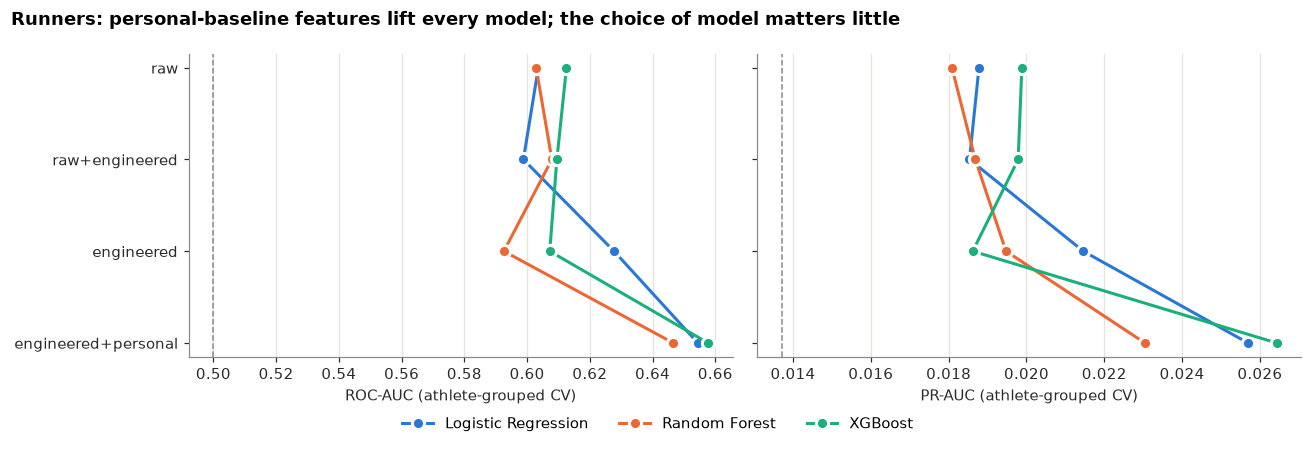

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
sets = list(data.RUNNER_FEATURE_SETS)
for ax, metric, label in [(axes[0], "roc_auc", "ROC-AUC (athlete-grouped CV)"),
                          (axes[1], "pr_auc", "PR-AUC (athlete-grouped CV)")]:
    for name in ["Logistic Regression", "Random Forest", "XGBoost"]:
        vals = [ablation.loc[(s, name), metric] for s in sets]
        ax.plot(vals, range(len(sets)), "o-", ms=8, color=plots.color_for(name), label=name, mec="white", mew=2)
    ax.set(xlabel=label)
    ax.grid(axis="y", visible=False)
axes[0].axvline(0.5, ls="--", color=plots.MUTED, lw=1)
axes[1].axvline(runners.y.iloc[train_idx].mean(), ls="--", color=plots.MUTED, lw=1)
axes[0].set_yticks(range(len(sets)), sets)
axes[0].invert_yaxis()
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Runners: personal-baseline features lift every model; the choice of model matters little",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(CH / "02_runners_feature_ablation.png")
plt.show()

**Final model: Logistic Regression on `engineered+personal`** (34 features). On this feature set the three models are tied within noise (fold-to-fold SD ≈ 0.04 AUC). Logistic regression is the simplest, is stable with only a few hundred injuries, and every prediction decomposes exactly into per-feature contributions, which is what a coach needs. SMOTE inside the training folds adds nothing over class weights.

> **Data-quality note.** In this dataset the injury rate depends on how long an athlete has been recorded: about 4% in the first week, almost 0% in weeks 2–4, then about 1.5%. That is a collection artifact, not physiology. An earlier version of the personal-baseline features had "missing" indicators that let the model learn it, which inflated cross-validated AUC to about 0.67. The features now default to 0 ("at their usual level") with no indicator.

Below, every model is fitted on all training athletes and scored **once** on the held-out athletes.

In [7]:
Xtr, ytr = runners.X.iloc[train_idx], runners.y.iloc[train_idx]
Xte, yte = runners.X.iloc[test_idx], runners.y.iloc[test_idx]

fitted, test_preds = {}, {}
for name, m in models.make_models(ytr, include_smote=False).items():
    fitted[name] = m.fit(Xtr, ytr)
    test_preds[name] = m.predict_proba(Xte)[:, 1]

final = fitted["Logistic Regression"]
p_test = test_preds["Logistic Regression"]

# Each model's alert threshold is chosen on its TRAINING out-of-fold predictions
# (never on the test set) to catch 50% of injuries, then applied unchanged to held-out athletes.
oofs = oof_by_set["engineered+personal"]
thresholds = {name: ev.threshold_for_recall(ytr, oofs[name], target_recall=0.5) for name in test_preds}
oof_final, threshold = oofs["Logistic Regression"], thresholds["Logistic Regression"]

runner_holdout = pd.DataFrame({name: {**ev.score(yte, p), "threshold": thresholds[name],
                                      **ev.threshold_metrics(yte, p, thresholds[name])}
                               for name, p in test_preds.items()}).T
runner_holdout.to_csv(RES / "runners_holdout.csv")
display(runner_holdout)

,roc_auc,pr_auc,pr_auc_baseline,brier,threshold,precision,recall,f1,flagged_rate
Logistic Regression,0.625,0.019,0.012,0.195,0.544,0.020,0.365,0.039,0.215
Random Forest,0.643,0.020,0.012,0.027,0.144,0.018,0.419,0.035,0.277
XGBoost,0.612,0.021,0.012,0.174,0.510,0.020,0.365,0.037,0.225


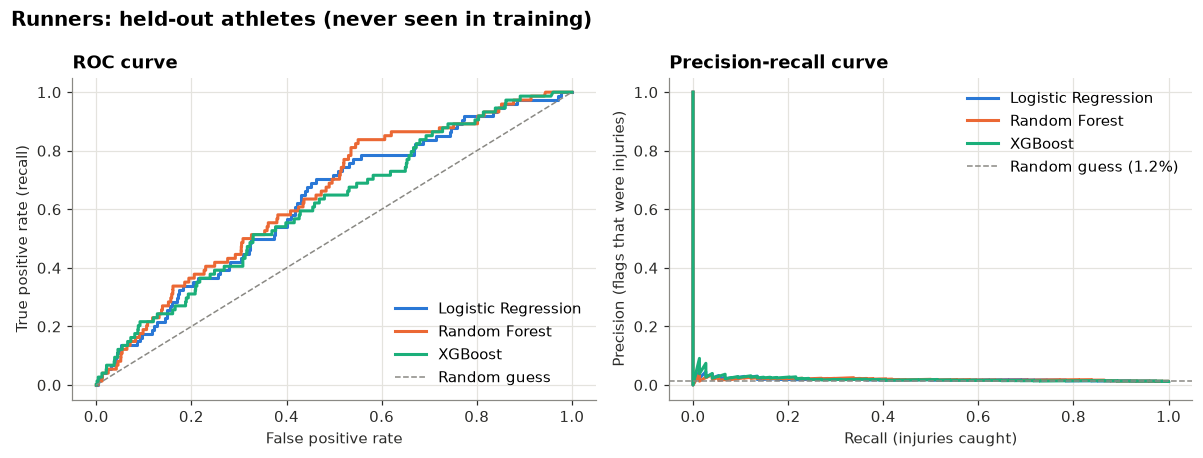

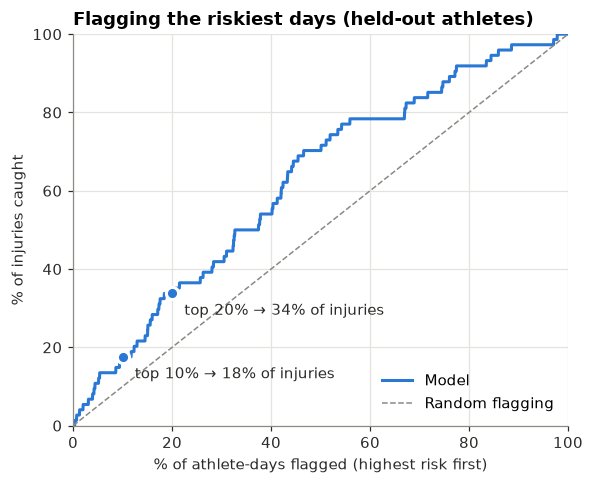

In [8]:
plots.roc_pr_panel(yte, test_preds, "Runners: held-out athletes (never seen in training)",
                   CH / "03_runners_holdout_roc_pr.png")
plt.show()
fig = plots.lift_plot(yte.values, p_test, "Flagging the riskiest days (held-out athletes)",
                      CH / "04_runners_lift.png")
plt.show()

**Calibration.** Class weights deliberately inflate probabilities toward the injured class, so the raw score is a *risk ranking*, not a probability. To report an actual probability, we recalibrate on training out-of-fold predictions (Platt scaling, fitted only on training athletes) and check it on the held-out athletes.

Brier score raw: 0.1947   calibrated: 0.0119   (predicting the base rate: 0.0119)


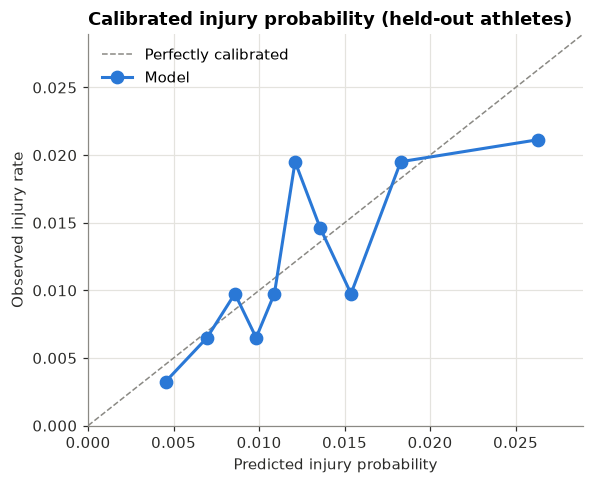

In [9]:
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))).reshape(-1, 1)
platt = LogisticRegression().fit(logit(oof_final), ytr)
calibrate = lambda p: platt.predict_proba(logit(p))[:, 1]
p_test_cal = calibrate(p_test)
print(f"Brier score raw: {ev.score(yte, p_test)['brier']:.4f}   calibrated: {ev.score(yte, p_test_cal)['brier']:.4f}"
      f"   (predicting the base rate: {ev.score(yte, np.full(len(yte), ytr.mean()))['brier']:.4f})")
plots.calibration_plot(yte, p_test_cal, "Calibrated injury probability (held-out athletes)",
                       CH / "05_runners_calibration.png")
plt.show()

**A second view: the same athletes, later in time.** A team using this tool would already have history for its own athletes. Here the model trains on the first 80% of every athlete's timeline and is tested on the last 20%.

In [10]:
rank = runners.meta.groupby("Athlete ID")["Date"].rank(pct=True)
early, late = (rank <= 0.8).values, (rank > 0.8).values
temporal = {}
for name, m in models.make_models(runners.y[early], include_smote=False).items():
    p = clone(m).fit(runners.X[early], runners.y[early]).predict_proba(runners.X[late])[:, 1]
    temporal[name] = ev.score(runners.y[late], p)
temporal = pd.DataFrame(temporal).T
temporal.to_csv(RES / "runners_temporal.csv")
display(temporal)

,roc_auc,pr_auc,pr_auc_baseline,brier
Logistic Regression,0.620,0.031,0.019,0.240
Random Forest,0.591,0.030,0.019,0.030
XGBoost,0.607,0.033,0.019,0.207


### Explainability (SHAP)

For a standardised logistic regression, the SHAP value of a feature equals its coefficient × its standardised value, so these explanations are exact. Positive means the feature pushes injury risk up.

**Read these as associations, not causes.** The strongest risk signals are training **strain above the athlete's own normal**, more hard (Z5, interval or sprint) km, high peak exertion, and a jump in recent km relative to the athlete's usual level. These match the workload-injury literature. Some effects run the "wrong" way for a causal reading. For example, *low* km yesterday raises predicted risk, most likely because runners ease off when a niggle starts, just before the injury is recorded (reverse causation).

Background dataset has 36529 samples but max_samples=2000. Subsampling to 2000 samples for SHAP value computation. To use all samples, set max_samples=36529 when initializing the masker.


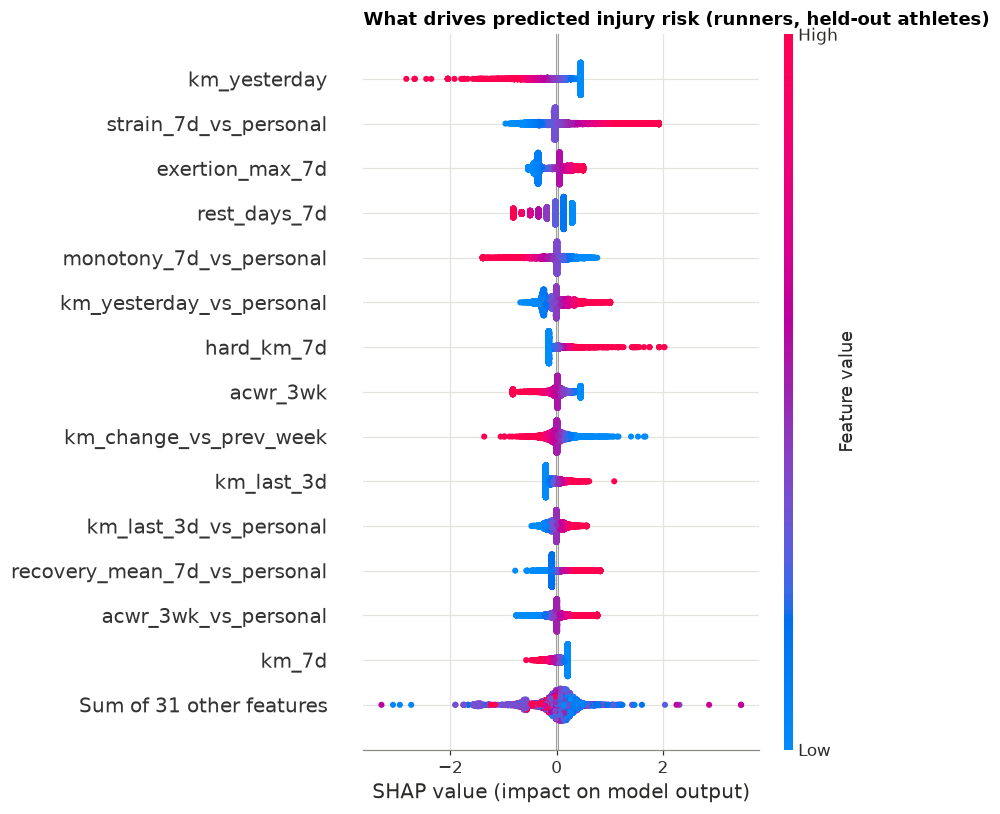

,coefficient (per 1 SD)
strain_7d_vs_personal,0.508
km_yesterday,-0.467
monotony_7d_vs_personal,-0.341
rest_days_7d,-0.288
exertion_max_7d,0.282
km_yesterday_vs_personal,0.264
rel total kms week 0_2,0.227
rel total kms week 1_2,-0.222
km_change_vs_prev_week,-0.194
monotony_7d,-0.194


In [11]:
pre, clf = final[:-1], final[-1]
Zte = pd.DataFrame(pre.transform(Xte), columns=pre.get_feature_names_out(), index=Xte.index)
explainer = shap.LinearExplainer(clf, shap.maskers.Independent(pre.transform(Xtr), max_samples=2000))
sv = explainer(Zte)
sv.feature_names = [n.replace("missingindicator_", "missing: ") for n in Zte.columns]
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("What drives predicted injury risk (runners, held-out athletes)", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(CH / "06_runners_shap_beeswarm.png")
plt.show()

# Note: these are associations, not causes. For example, LOW km yesterday raising risk most likely
# reflects runners easing off when a niggle starts (reverse causation), not that running less is harmful.
coefs = (pd.Series(clf.coef_[0], index=sv.feature_names).sort_values(key=np.abs, ascending=False)
         .head(12).rename("coefficient (per 1 SD)"))
display(coefs.to_frame())

In [12]:
# Example: explain the highest-risk day of one held-out athlete
contrib = explain.linear_contributions(final, Xte)
i = int(np.argmax(p_test))
row_id = Xte.index[i]
print(f"Athlete {runners.meta.loc[row_id, 'Athlete ID']}, day {runners.meta.loc[row_id, 'Date']}: "
      f"calibrated risk {p_test_cal[i]:.1%} (base rate {ytr.mean():.1%}), injured that day: {bool(yte.iloc[i])}")
display(explain.top_reasons(contrib.loc[row_id], Xte.loc[row_id]))

Athlete 5, day 177: calibrated risk 8.6% (base rate 1.4%), injured that day: False


,feature,value,log_odds_contribution
0,hard_km_7d,65.000,1.928
1,strain_7d_vs_personal,1.930,0.909
2,km_last_3d_vs_personal,3.893,0.545
3,km_last_3d,52.000,0.288
4,km_yesterday,3.000,0.261


In [13]:
# Save the final model and held-out predictions for the dashboard (app/streamlit_app.py)
bundle = {"model": final, "features": list(runners.X.columns), "threshold": threshold,
          "platt": platt, "base_rate": float(ytr.mean()),
          "holdout_metrics": runner_holdout.loc["Logistic Regression"].to_dict()}
joblib.dump(bundle, paths.MODELS_DIR / "runner_model.joblib")
holdout_frame = pd.concat([runners.meta.iloc[test_idx], yte.rename("injury"),
                           pd.Series(p_test, index=Xte.index, name="risk_score"),
                           pd.Series(p_test_cal, index=Xte.index, name="risk_probability"), Xte], axis=1)
holdout_frame.to_csv(paths.MODELS_DIR / "runner_holdout_predictions.csv.gz", index=False)
print("Saved", paths.MODELS_DIR / "runner_model.joblib")

Saved C:\devKiNG_Projects\12_AI_ML_Projects\UniAtheleIQ\outputs\models\runner_model.joblib


## 4. Football: will a player have a severe injury season?

Only information available **before** the season starts is used: age, physique, position, FIFA attributes, and previous-season and career-to-date injury and minutes. Current-season minutes and games are excluded because injured players play less, which leaks the answer. Career totals are excluded too, because they include future seasons. Players are grouped, so the same player never appears in both train and test.

In [14]:
ftr, fte = ev.holdout_split(football)
fb_cv, _ = ev.compare_models(models.make_models(football.y.iloc[ftr]), football.X.iloc[ftr],
                             football.y.iloc[ftr], football.groups.iloc[ftr])
fb_cv.to_csv(RES / "football_cv.csv")
display(fb_cv[["roc_auc", "roc_auc_fold_std", "pr_auc", "pr_auc_baseline"]])

best_fb = fb_cv.index[0]
fb_model = models.make_models(football.y.iloc[ftr])[best_fb].fit(football.X.iloc[ftr], football.y.iloc[ftr])
p_fb = fb_model.predict_proba(football.X.iloc[fte])[:, 1]
fb_holdout = pd.Series(ev.score(football.y.iloc[fte], p_fb), name=best_fb)
fb_holdout.to_frame().T.to_csv(RES / "football_holdout.csv")
print(f"Held-out players, {best_fb}:")
display(fb_holdout.to_frame().T)

,roc_auc,roc_auc_fold_std,pr_auc,pr_auc_baseline
model,,,,
Logistic Regression,0.600,0.050,0.769,0.681
Random Forest,0.604,0.022,0.756,0.681
XGBoost,0.602,0.018,0.754,0.681
Random Forest + SMOTE (train folds only),0.594,0.021,0.749,0.681


Held-out players, Logistic Regression:


,roc_auc,pr_auc,pr_auc_baseline,brier
Logistic Regression,0.652,0.799,0.708,0.238


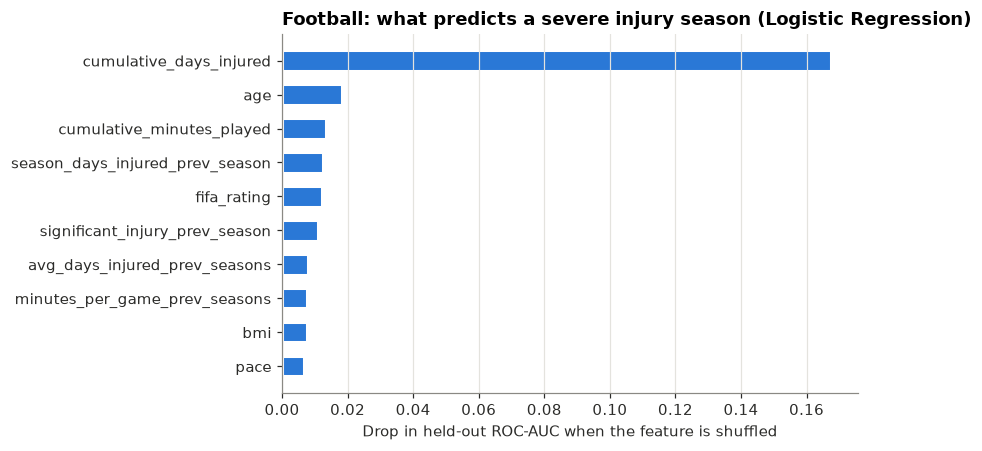

In [15]:
pi = permutation_importance(fb_model, football.X.iloc[fte], football.y.iloc[fte], scoring="roc_auc",
                            n_repeats=20, random_state=42)
imp = pd.Series(pi.importances_mean, index=football.X.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(imp.index, imp.values, color=plots.SERIES[0], height=0.6, edgecolor="white", linewidth=2)
ax.axvline(0, color=plots.MUTED, lw=1)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Drop in held-out ROC-AUC when the feature is shuffled",
       title=f"Football: what predicts a severe injury season ({best_fb})")
fig.tight_layout()
fig.savefig(CH / "07_football_permutation_importance.png")
plt.show()

## 5. Multi-sport wearable dataset: a data-quality warning

Every numeric column in this dataset is spread evenly between round limits (heart rate 100–179, SpO₂ 95–100, fatigue 0.2–0.8, and so on). Real physiological signals look roughly bell-shaped, so this looks like **synthetic data**. Results on it say little about real athletes.

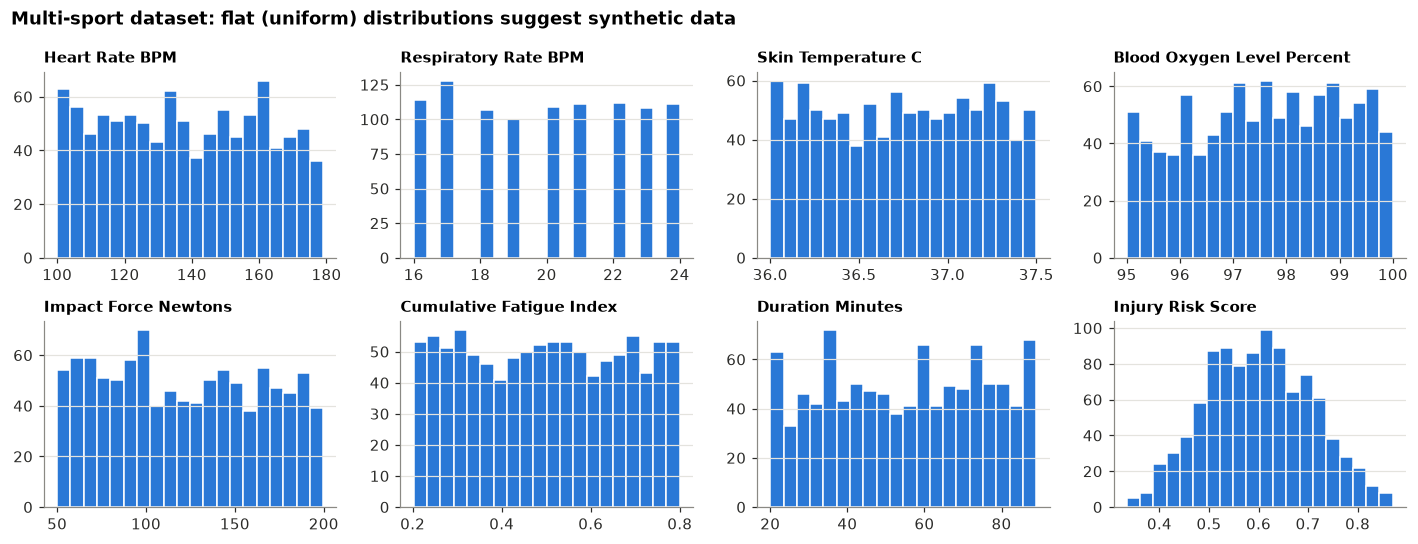

,roc_auc,roc_auc_fold_std,pr_auc,pr_auc_baseline
model,,,,
Logistic Regression,0.596,0.037,0.697,0.617
Random Forest + SMOTE (train folds only),0.585,0.041,0.697,0.617
Random Forest,0.603,0.038,0.694,0.617
XGBoost,0.589,0.032,0.683,0.617


ROC-AUC of the provided Injury_Risk_Score on its own: 0.613


In [16]:
raw_multi = pd.read_csv(paths.MULTISPORT_CSV)
num = ["Heart_Rate_BPM", "Respiratory_Rate_BPM", "Skin_Temperature_C", "Blood_Oxygen_Level_Percent",
       "Impact_Force_Newtons", "Cumulative_Fatigue_Index", "Duration_Minutes", "Injury_Risk_Score"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for ax, c in zip(axes.flat, num):
    ax.hist(raw_multi[c], bins=20, color=plots.SERIES[0], edgecolor="white", linewidth=1)
    ax.set_title(c.replace("_", " "), fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Multi-sport dataset: flat (uniform) distributions suggest synthetic data", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(CH / "08_multisport_distributions.png")
plt.show()

ms_cv, _ = ev.compare_models(models.make_models(multi.y), multi.X, multi.y, multi.groups)
ms_cv.to_csv(RES / "multisport_cv.csv")
display(ms_cv[["roc_auc", "roc_auc_fold_std", "pr_auc", "pr_auc_baseline"]])
print("ROC-AUC of the provided Injury_Risk_Score on its own:",
      round(roc_auc_score(raw_multi.Injury_Occurred, raw_multi.Injury_Risk_Score), 3))

## 6. Does injury risk transfer across sports?

This tests the cross-sport claim directly. The two session-level datasets share two concepts, **training load** (km for runners, minutes for the wearable data) and **effort** (perceived exertion, fatigue index). Each is z-scored *within its own dataset* so units no longer matter. We then train on one sport and test on the other, and compare with training and testing within the same sport.

In [17]:
h = data.harmonised_load_effort()
F = ["load_z", "effort_z"]
names = h["dataset"].unique()
rows = []
for a in names:
    A = h[h.dataset == a]
    oof, _ = ev.grouped_oof(models.make_models(A.injury, include_smote=False)["Logistic Regression"],
                            A[F], A.injury, A.group)
    rows.append({"train": a, "test": a, "roc_auc": roc_auc_score(A.injury, oof)})
    m = models.make_models(A.injury, include_smote=False)["Logistic Regression"].fit(A[F], A.injury)
    for b in names:
        if b != a:
            B = h[h.dataset == b]
            rows.append({"train": a, "test": b, "roc_auc": roc_auc_score(B.injury, m.predict_proba(B[F])[:, 1])})
transfer = pd.DataFrame(rows)
transfer.to_csv(RES / "cross_sport_transfer.csv", index=False)
display(transfer.pivot(index="train", columns="test", values="roc_auc"))

test,Multi-sport (wearable),Runners
train,,
Multi-sport (wearable),0.589,0.610
Runners,0.593,0.604


**Reading the transfer table.** Using only the two concepts the datasets genuinely share, a model trained on one source ranks injuries in the other **about as well as a model trained on that source itself** (all ROC-AUC ≈ 0.59–0.61). So the direction of the load and effort → risk relationship does carry across these sources, which supports the cross-sport idea in a narrow sense. Two caveats keep this weak evidence: the signal is small in every cell, and the multi-sport dataset appears synthetic (§5). A convincing test needs real datasets that record the same measurements (for example session RPE × duration, and GPS load) for several sports.

## 7. Summary

In [18]:
summary = pd.DataFrame([
    {"experiment": "v1 protocol (leaky), Random Forest", "eval": "SMOTE before split",
     "roc_auc": audit.iloc[0].roc_auc, "pr_auc": audit.iloc[0].pr_auc, "pr_auc_random": 0.5},
    {"experiment": "Runners, Logistic Regression (final)", "eval": "held-out athletes",
     "roc_auc": runner_holdout.loc["Logistic Regression", "roc_auc"],
     "pr_auc": runner_holdout.loc["Logistic Regression", "pr_auc"], "pr_auc_random": yte.mean()},
    {"experiment": "Runners, Logistic Regression", "eval": "same athletes, later 20% of time",
     "roc_auc": temporal.loc["Logistic Regression", "roc_auc"],
     "pr_auc": temporal.loc["Logistic Regression", "pr_auc"], "pr_auc_random": runners.y[late].mean()},
    {"experiment": f"Football severe-injury season, {best_fb}", "eval": "held-out players",
     "roc_auc": fb_holdout.roc_auc, "pr_auc": fb_holdout.pr_auc, "pr_auc_random": football.y.iloc[fte].mean()},
    {"experiment": f"Multi-sport wearable, {ms_cv.index[0]}", "eval": "5-fold CV",
     "roc_auc": ms_cv.iloc[0].roc_auc, "pr_auc": ms_cv.iloc[0].pr_auc, "pr_auc_random": multi.y.mean()},
]).set_index("experiment")
summary["pr_auc_lift"] = summary.pr_auc / summary.pr_auc_random
summary.to_csv(RES / "summary.csv")
display(summary)

,eval,roc_auc,pr_auc,pr_auc_random,pr_auc_lift
experiment,,,,,
"v1 protocol (leaky), Random Forest",SMOTE before split,0.991,0.990,0.500,1.980
"Runners, Logistic Regression (final)",held-out athletes,0.625,0.019,0.012,1.619
"Runners, Logistic Regression","same athletes, later 20% of time",0.620,0.031,0.019,1.654
"Football severe-injury season, Logistic Regression",held-out players,0.652,0.799,0.708,1.127
"Multi-sport wearable, Logistic Regression",5-fold CV,0.596,0.697,0.617,1.130


### Conclusions

1. **The v1 headline (96% accuracy) was an artifact** of SMOTE before splitting, duplicate rows, and the sport column encoding which dataset a row came from.
2. **Injury prediction from training logs is hard, and the honest signal is modest.** On runners the model has never seen, ROC-AUC is about 0.62 (0.65 in athlete-grouped CV), and PR-AUC is about 1.5× random. That is useful for ranking days for a coach check-in, not for diagnosing individuals. Modest AUCs like this are typical in injury-prediction research.
3. **Personal baselines matter more than model complexity.** Deviation from an athlete's own normal load and wellness improved every model by about 0.02–0.05 AUC. Logistic regression, Random Forest and XGBoost were then tied.
4. **Cross-sport:** with dataset-normalised load and effort, models trained on one source transfer to the other about as well as within-source models, but the signal is weak and one source appears synthetic.
5. **Data quality:** the multi-sport dataset appears synthetic, the runner injury rate depends on how long an athlete has been recorded (a collection artifact), and the basketball and NBA files contain only injured players, so they cannot train a risk model.

### Limitations and next steps
- Only 74 runners and about 580 injuries. Results vary by athlete (see the fold standard deviations).
- Injury labels do not record type or severity for the runners.
- Next steps: sequence models (LSTM or temporal CNN) over the full daily history, survival or time-to-injury framing, and prospective validation with a real team.